In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)

In [16]:
df = pd.DataFrame()
df['X'] = X.reshape(100)
df['y'] = y

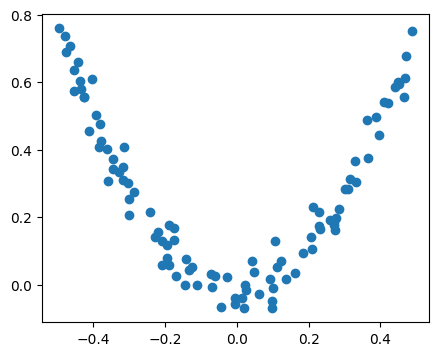

In [24]:
plt.figure(figsize= (5,4))
plt.scatter(df['X'], df['y'])
plt.show()

In [19]:
df['pred1'] = df['y'].mean()

In [21]:
df['res1'] = df['y'] - df['pred1']

In [25]:
from sklearn.tree import DecisionTreeRegressor

tree1 = DecisionTreeRegressor(max_leaf_nodes=8)

In [31]:
tree1.fit(df['X'].values.reshape(100,1),df['res1'].values)

DecisionTreeRegressor(max_leaf_nodes=8)

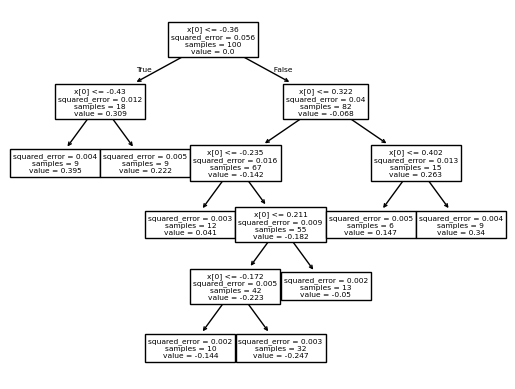

In [32]:
from sklearn.tree import plot_tree
plot_tree(tree1)
plt.show()

In [33]:
# generating X_test
X_test = np.linspace(-0.5, 0.5, 500)

In [38]:
y_pred = df['y'].mean() + tree1.predict(X_test.reshape(500,1))

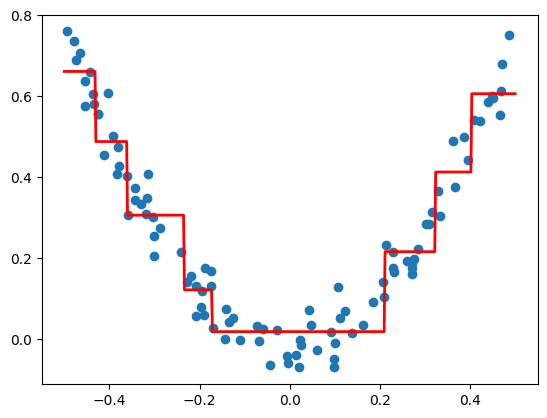

In [41]:
plt.plot(X_test, y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['y'])

plt.show()

In [42]:
df['pred2'] = 0.265458 + tree1.predict(df['X'].values.reshape(100,1))

In [44]:
df['res2'] = df['y'] - df['pred2']

In [46]:
tree2 = DecisionTreeRegressor(max_leaf_nodes= 8)

In [47]:
tree2.fit(df['X'].values.reshape(100,1), df['res2'].values)

DecisionTreeRegressor(max_leaf_nodes=8)

Text(0.5, 1.0, 'X vs y')

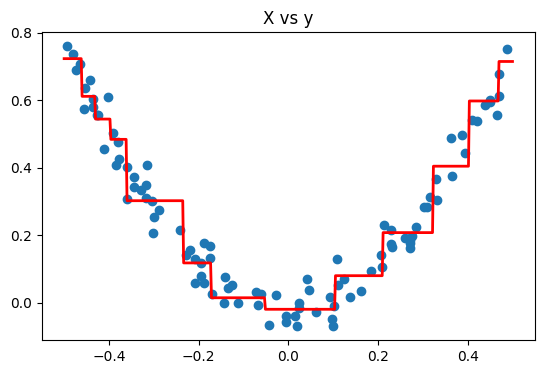

In [48]:
y_pred = 0.265458 + sum(regressor.predict(X_test.reshape(-1, 1)) for regressor in [tree1,tree2])

plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test, y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['y'])
plt.title('X vs y')

### Uses recursion. Interesting

In [49]:
def gradient_boost(X,y,number,lr,count=1,regs=[],foo=None):

  if number == 0:
    return 
  else:
    # do gradient boosting

    if count > 1:
      y = y - regs[-1].predict(X)
    else:
      foo = y

    tree_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
    tree_reg.fit(X, y)

    regs.append(tree_reg)

    x1 = np.linspace(-0.5, 0.5, 500)
    y_pred = sum(lr * regressor.predict(x1.reshape(-1, 1)) for regressor in regs)

    print(number)
    plt.figure()
    plt.plot(x1, y_pred, linewidth=2)
    plt.plot(X[:, 0], foo,"r.")
    plt.show()

    gradient_boost(X,y,number-1,lr,count+1,regs,foo=foo)

5


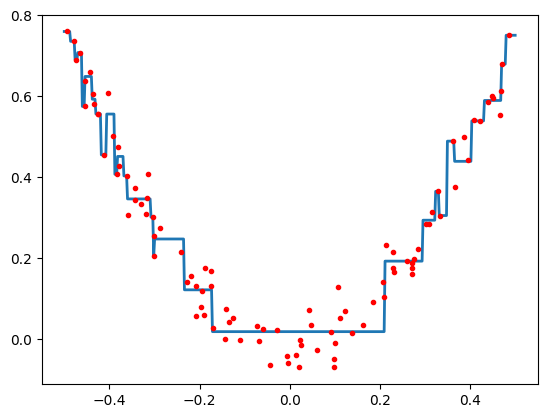

4


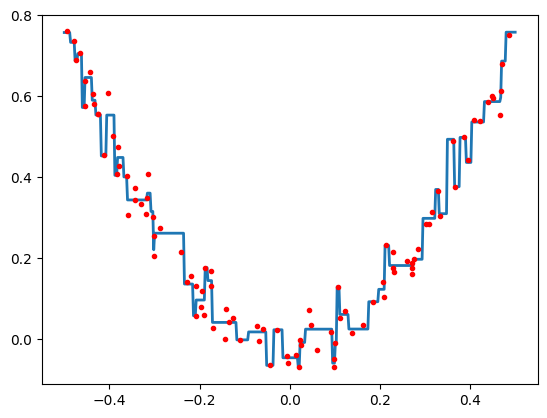

3


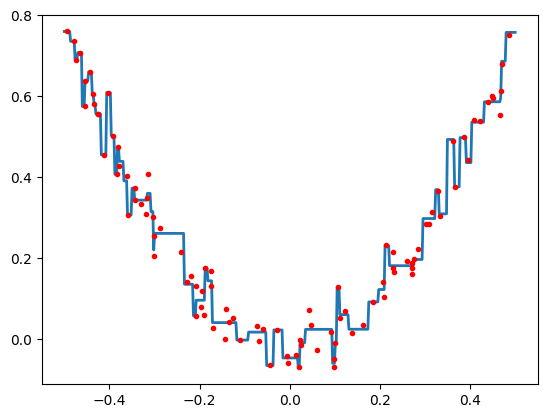

2


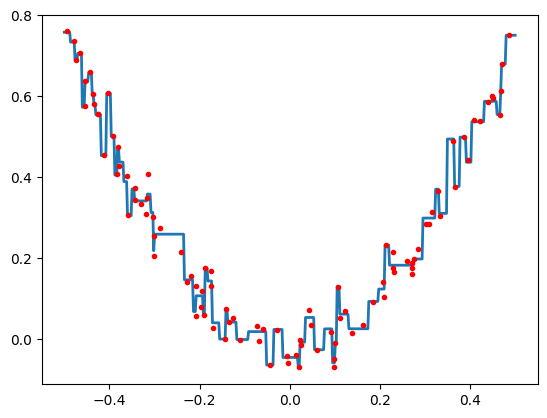

1


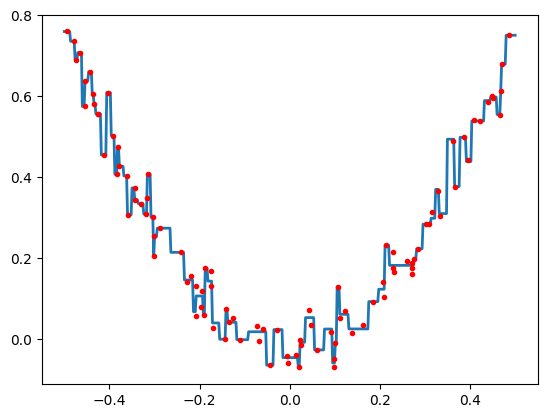

In [50]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)
gradient_boost(X,y,5,lr=1)